# Telco Churn: Python analysis

Repeats the Excel analysis in Python (pandas, scikit-learn, SHAP) using the **same train/test split and the same 5 features**, so the results can be compared directly with the Excel model.

## 1. Load and clean data

Blank `TotalCharges` values (11 customers, all with `tenure = 0`) are replaced with 0, the same decision taken in Excel.

In [5]:
import sys
import pandas as pd

sys.path.insert(0, ".")
from churn_utils import clean_total_charges, add_churn_flag, add_model_features, add_split

raw = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(raw.shape)

# 11 customers have a blank TotalCharges (text), all with tenure = 0
raw[raw["TotalCharges"].str.strip() == ""][["customerID", "tenure", "TotalCharges"]]

(7043, 21)


,customerID,tenure,TotalCharges
488,4472-LVYGI,0,
753,3115-CZMZD,0,
936,5709-LVOEQ,0,
1082,4367-NUYAO,0,
1340,1371-DWPAZ,0,
3331,7644-OMVMY,0,
3826,3213-VVOLG,0,
4380,2520-SGTTA,0,
5218,2923-ARZLG,0,
6670,4075-WKNIU,0,


In [6]:
df = clean_total_charges(raw)
df = add_churn_flag(df)
df = add_model_features(df)
df = add_split(df)

print(df["TotalCharges"].isna().sum(), df["ChurnFlag"].mean())
print(df["IsMonthToMonth"].sum(), df["IsFiber"].sum(), df["IsElectronicCheck"].sum())
print(df["Split"].value_counts())
print(df.shape)
df.head()

0 0.2653698707936959
3875 3096 2365
Split
Train    5635
Test     1408
Name: count, dtype: int64
(7043, 28)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,MonthlyCharges,TotalCharges,Churn,ChurnFlag,IsMonthToMonth,IsFiber,IsElectronicCheck,tenure_s,MonthlyCharges_s,Split
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,29.85,29.85,No,0,1,0,1,0.013889,0.248750,Train
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,56.95,1889.50,No,0,0,0,0,0.472222,0.474583,Train
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,53.85,108.15,Yes,1,1,0,0,0.027778,0.448750,Train
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,42.30,1840.75,No,0,0,0,0,0.625000,0.352500,Train
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,70.70,151.65,Yes,1,1,1,1,0.027778,0.589167,Test


## 2. Logistic regression (same split and features as the Excel model)

No regularization, so the model matches the one fitted with Solver. Evaluated on the 1,408 test customers at threshold 0.30.

In [7]:
from sklearn.linear_model import LogisticRegression
import numpy as np

features = ["tenure_s", "MonthlyCharges_s", "IsMonthToMonth", "IsFiber", "IsElectronicCheck"]

train = df[df["Split"] == "Train"]
test = df[df["Split"] == "Test"]

model = LogisticRegression(C=np.inf, max_iter=1000)
model.fit(train[features], train["ChurnFlag"])

print("Intercept:", model.intercept_[0])
for name, coef in zip(features, model.coef_[0]):
    print(name, coef)

Intercept: -2.5023228994296964
tenure_s -2.4764200711229454
MonthlyCharges_s 1.678723706076621
IsMonthToMonth 1.1306775445148851
IsFiber 0.7803642058190177
IsElectronicCheck 0.5905752447459223


In [8]:
from sklearn.metrics import roc_auc_score, confusion_matrix, precision_score, recall_score, f1_score

proba = model.predict_proba(test[features])[:, 1]
pred = (proba >= 0.30).astype(int)
y = test["ChurnFlag"]

print("AUC:", roc_auc_score(y, proba))
print(confusion_matrix(y, pred))
print("Precision:", precision_score(y, pred))
print("Recall:", recall_score(y, pred))
print("F1:", f1_score(y, pred))

AUC: 0.8182770842965017
[[796 234]
 [ 99 279]]
Precision: 0.543859649122807
Recall: 0.7380952380952381
F1: 0.6262626262626263


## 3. Random Forest: 5 variables vs all variables

First with the same 5 features as the regression, then with all 45 columns (categories expanded to 0/1).

In [9]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=20,
    random_state=42,
)
rf.fit(train[features], train["ChurnFlag"])

proba_rf = rf.predict_proba(test[features])[:, 1]
print("AUC Random Forest:", roc_auc_score(y, proba_rf))
print("AUC Logistic Regression:", roc_auc_score(y, proba))

AUC Random Forest: 0.8297195253505932
AUC Logistic Regression: 0.8182770842965017


In [10]:
from sklearn.ensemble import RandomForestClassifier

cat_cols = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
            "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
            "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
            "PaperlessBilling", "PaymentMethod"]
num_cols = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

X_all = pd.get_dummies(df[cat_cols + num_cols], columns=cat_cols, dtype=int)
X_train = X_all[df["Split"] == "Train"]
X_test = X_all[df["Split"] == "Test"]

rf_all = RandomForestClassifier(n_estimators=300, min_samples_leaf=20, random_state=42)
rf_all.fit(X_train, train["ChurnFlag"])

proba_all = rf_all.predict_proba(X_test)[:, 1]
print(X_all.shape)
print("AUC Random Forest (all variables):", roc_auc_score(y, proba_all))

(7043, 45)
AUC Random Forest (all variables): 0.8382917244567729


## 4. SHAP: what drives churn predictions

Color shows the feature value (low/high), not risk. Features are associated with higher or lower predicted churn; this does not prove causes.

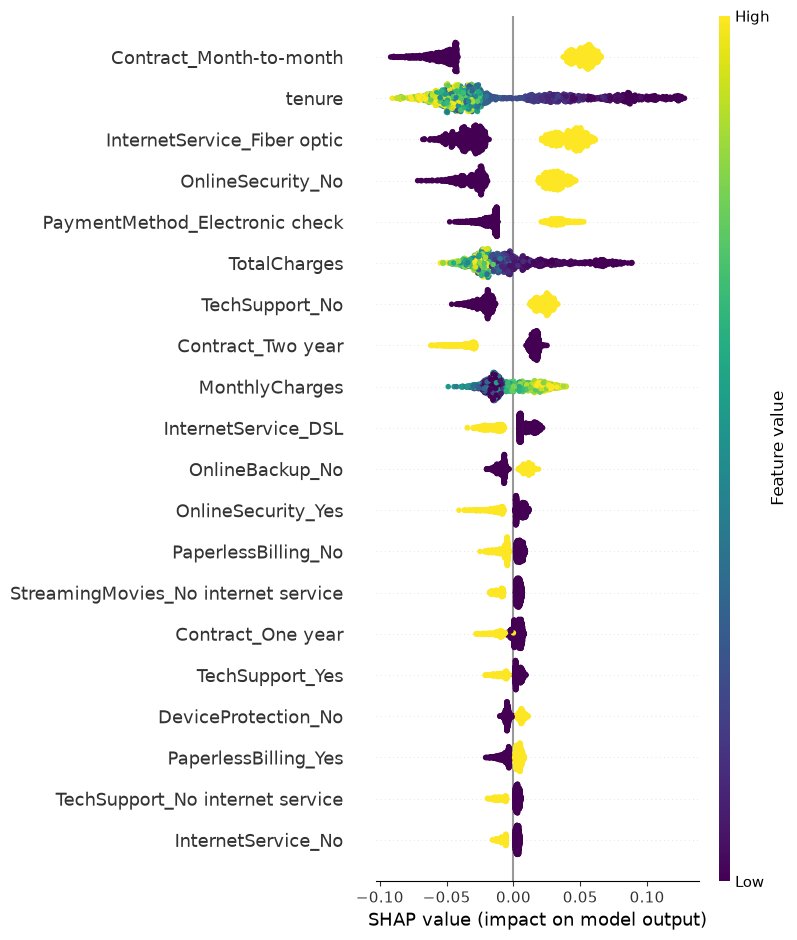

In [11]:
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(rf_all)
sv = explainer.shap_values(X_test)
if isinstance(sv, list):
    sv = sv[1]
elif sv.ndim == 3:
    sv = sv[:, :, 1]

shap.summary_plot(sv, X_test, cmap="viridis", show=False)
plt.savefig("../docs/images/07_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusions

- Python and Excel agree: AUC 0.818 (scikit-learn) vs 0.815 (Excel Solver).
- Tree ensembles gain about 0.02 AUC over logistic regression (0.838 vs 0.818), measured on a single train/test split.
- Main drivers in SHAP: contract type, tenure, fiber optic, no online security and electronic check payment (associated with higher churn, not proven causes).